# 🫀 Exercise: Heart Disease Prediction Using Machine Learning and PCA

| | |
|---|---|
| **Dataset** | Heart Failure Prediction Dataset |
| **Source** | [Kaggle – Heart Failure Prediction](https://www.kaggle.com/fedesoriano/heart-failure-prediction) |
| **File name** | `heart.csv` |
| **Folder** | `Exercise` |

**Student Name:** ______________________ &nbsp;&nbsp; **Roll No.:** ____________ &nbsp;&nbsp; **Date:** ____________

---

## Problem Statement

Download the `heart.csv` dataset from Kaggle and save it in the `Exercise` folder. Perform data preprocessing, model building, hyperparameter tuning and dimensionality reduction to predict whether a patient has heart disease (`HeartDisease` = 1) or not (`HeartDisease` = 0).

### Instructions
- Write your code in the **empty code cells** provided below each task.
- Write your explanations in the **✍️ Your answer** cells.
- Run all cells from top to bottom before submitting (**Kernel → Restart & Run All**).
- Use `random_state=42` wherever randomness is involved so that results are reproducible.

## Overall Workflow

You will build the pipeline below. Path A trains models on all preprocessed features; Path B trains the same models on PCA-reduced features. Step 9 compares the two.

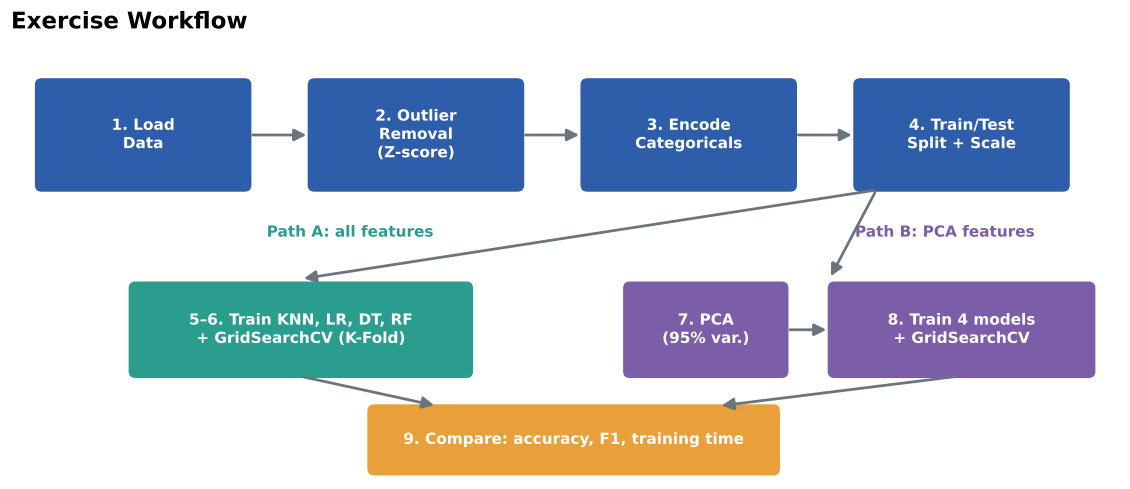

## Data Dictionary

| Feature | Description | Type |
|---|---|---|
| `Age` | Age of the patient (years) | Numerical |
| `Sex` | Sex of the patient (`M`, `F`) | Categorical (binary) |
| `ChestPainType` | `TA` typical angina, `ATA` atypical angina, `NAP` non-anginal pain, `ASY` asymptomatic | Categorical (nominal) |
| `RestingBP` | Resting blood pressure (mm Hg) | Numerical |
| `Cholesterol` | Serum cholesterol (mg/dl) | Numerical |
| `FastingBS` | Fasting blood sugar > 120 mg/dl (1 = yes, 0 = no) | Binary (already numeric) |
| `RestingECG` | Resting ECG result (`Normal`, `ST`, `LVH`) | Categorical (nominal) |
| `MaxHR` | Maximum heart rate achieved | Numerical |
| `ExerciseAngina` | Exercise-induced angina (`Y`, `N`) | Categorical (binary) |
| `Oldpeak` | ST depression induced by exercise | Numerical |
| `ST_Slope` | Slope of the peak exercise ST segment (`Up`, `Flat`, `Down`) | Categorical |
| `HeartDisease` | **Target** — 1 = heart disease, 0 = normal | Binary |

## Import Libraries

Import all the libraries you will need (pandas, numpy, matplotlib/seaborn, scipy, scikit-learn modules, `time`, etc.).

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.decomposition import PCA
from sklearn.base import clone
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
RANDOM_STATE = 42
pd.set_option("display.max_columns", 30)

---
## Task 1: Load the Dataset

1. Load `Exercise/heart.csv` into a Pandas DataFrame.
2. Display the first five records.
3. Examine the dataset's **dimensions**, **column names**, **data types** and **missing values**.

### 1.1 Load the dataset and display the first five records

In [2]:
df = pd.read_csv("Exercise/heart.csv")
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


### 1.2 Dimensions, column names and data types

In [3]:
print("Dimensions (rows, columns):", df.shape)
print("\nColumn names:", list(df.columns))
print("\nData types:")
print(df.dtypes)
print()
df.info()

Dimensions (rows, columns): (918, 12)

Column names: ['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope', 'HeartDisease']

Data types:
Age                 int64
Sex                   str
ChestPainType         str
RestingBP           int64
Cholesterol         int64
FastingBS           int64
RestingECG            str
MaxHR               int64
ExerciseAngina        str
Oldpeak           float64
ST_Slope              str
HeartDisease        int64
dtype: object

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  


### 1.3 Check for missing values

In [4]:
print("Missing values per column (NaN):")
print(df.isnull().sum())
print("\nTotal NaN:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nSummary statistics of numerical columns:")
display(df.describe().T)

print("\nMedically impossible zeros (hidden missing values):")
print("Cholesterol == 0 :", (df["Cholesterol"] == 0).sum())
print("RestingBP   == 0 :", (df["RestingBP"] == 0).sum())

Missing values per column (NaN):
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

Total NaN: 0
Duplicate rows: 0

Summary statistics of numerical columns:


,count,mean,std,min,25%,50%,75%,max
Age,918.0,53.510893,9.432617,28.0,47.00,54.0,60.0,77.0
RestingBP,918.0,132.396514,18.514154,0.0,120.00,130.0,140.0,200.0
Cholesterol,918.0,198.799564,109.384145,0.0,173.25,223.0,267.0,603.0
FastingBS,918.0,0.233115,0.423046,0.0,0.00,0.0,0.0,1.0
MaxHR,918.0,136.809368,25.460334,60.0,120.00,138.0,156.0,202.0
Oldpeak,918.0,0.887364,1.066570,-2.6,0.00,0.6,1.5,6.2
HeartDisease,918.0,0.553377,0.497414,0.0,0.00,1.0,1.0,1.0



Medically impossible zeros (hidden missing values):
Cholesterol == 0 : 172
RestingBP   == 0 : 1


### 1.4 (Optional) Class balance
Check how many records belong to each class of `HeartDisease`. Is the dataset balanced?

HeartDisease
0    410
1    508
Name: count, dtype: int64

Percentages:
HeartDisease
0    44.66
1    55.34
Name: proportion, dtype: float64


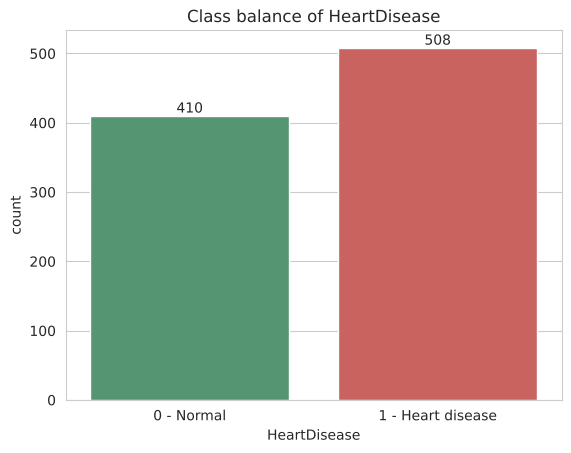

In [5]:
counts = df["HeartDisease"].value_counts().sort_index()
print(counts)
print("\nPercentages:")
print((df["HeartDisease"].value_counts(normalize=True).sort_index() * 100).round(2))

ax = sns.countplot(x="HeartDisease", data=df, palette=["#4c9f70", "#d9534f"])
ax.set_title("Class balance of HeartDisease")
ax.set_xticklabels(["0 - Normal", "1 - Heart disease"])
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.show()

**Q1.** Summarise your observations: number of rows/columns, which columns are text-based, and whether any missing values exist.

> 💡 *Hint:* Look closely at `Cholesterol` and `RestingBP` using `df.describe()`. Are there values that are medically impossible (e.g., 0)? Note them — such values are sometimes hidden missing values.

> ✍️ **Your answer:**
>
> **Rows / columns:** the dataset has **918 rows and 12 columns** (11 clinical features + the target `HeartDisease`).
>
> **Text-based columns (5):** `Sex`, `ChestPainType`, `RestingECG`, `ExerciseAngina` and `ST_Slope`. The other seven columns are numeric (`FastingBS` and `HeartDisease` are already 0/1).
>
> **Missing values:** `isnull()` reports **no missing values** (0 NaN) and there are no duplicate rows. However, `df.describe()` reveals **hidden missing values**: **172 patients have `Cholesterol = 0`** (about 18.7% of the data) and **1 patient has `RestingBP = 0`**. Both are medically impossible and are really "not measured" entries that are stored as zero. The exercise does not ask us to impute them, so they are kept (see the note in Q2).
>
> **Class balance:** 508 patients (55.3%) have heart disease and 410 (44.7%) do not, so the data set is **reasonably balanced**; no resampling is needed and accuracy is a meaningful metric, though recall still matters (Q5).

---
## Task 2: Outlier Detection and Removal (Z-score Method)

The Z-score measures how many standard deviations a value lies from the mean of its feature:

$$z = \frac{x - \mu}{\sigma}$$

A record is treated as an **outlier** if **any** of its numerical features has $z > +3$ or $z < -3$.

![zscore](attachment:zscore.png)

**Steps**
1. Select the numerical (continuous) features: `Age`, `RestingBP`, `Cholesterol`, `MaxHR`, `Oldpeak`.
2. Calculate the Z-score for each of these features.
3. Identify and count the records containing outliers.
4. Remove those records and report the shape of the dataset before and after removal.

> ⚠️ Do **not** compute Z-scores on the target column or on encoded/binary columns.

### 2.1 Visualise the numerical features (e.g., boxplots) before outlier removal

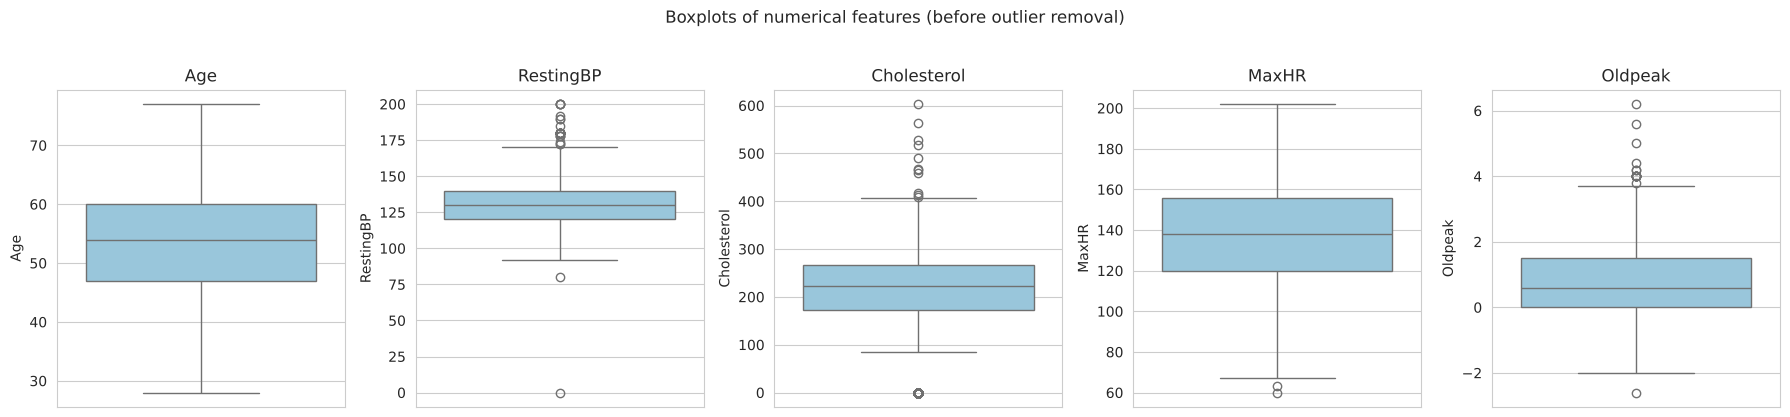

In [6]:
num_cols = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax, color="#8ecae6")
    ax.set_title(col)
plt.suptitle("Boxplots of numerical features (before outlier removal)", y=1.03)
plt.tight_layout()
plt.show()

### 2.2 Calculate Z-scores for the numerical features

In [7]:
z_scores = pd.DataFrame(stats.zscore(df[num_cols]), columns=num_cols, index=df.index)
z_scores.head()

,Age,RestingBP,Cholesterol,MaxHR,Oldpeak
0,-1.433140,0.410909,0.825070,1.382928,-0.832432
1,-0.478484,1.491752,-0.171961,0.754157,0.105664
2,-1.751359,-0.129513,0.770188,-1.525138,-0.832432
3,-0.584556,0.302825,0.139040,-1.132156,0.574711
4,0.051881,0.951331,-0.034755,-0.581981,-0.832432


### 2.3 Identify and count the outlier records

In [8]:
outlier_flags = z_scores.abs() > 3          # True where |z| > 3
outlier_mask = outlier_flags.any(axis=1)      # a record is an outlier if ANY feature is

print("Outliers per feature (|z| > 3):")
print(outlier_flags.sum())
print("\nTotal records containing at least one outlier:", outlier_mask.sum())

print("\nOutlier records:")
display(df[outlier_mask])

Outliers per feature (|z| > 3):
Age            0
RestingBP      8
Cholesterol    3
MaxHR          1
Oldpeak        7
dtype: int64

Total records containing at least one outlier: 19

Outlier records:


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
76,32,M,ASY,118,529,0,Normal,130,N,0.0,Flat,1
109,39,M,ATA,190,241,0,Normal,106,N,0.0,Up,0
149,54,M,ASY,130,603,1,Normal,125,Y,1.0,Flat,1
166,50,M,ASY,140,231,0,ST,140,Y,5.0,Flat,1
241,54,M,ASY,200,198,0,Normal,142,Y,2.0,Flat,1
324,46,M,ASY,100,0,1,ST,133,N,-2.6,Flat,1
365,64,F,ASY,200,0,0,Normal,140,Y,1.0,Flat,1
390,51,M,ASY,140,0,0,Normal,60,N,0.0,Flat,1
399,61,M,NAP,200,0,1,ST,70,N,0.0,Flat,1
449,55,M,NAP,0,0,0,Normal,155,N,1.5,Flat,1


### 2.4 Remove the outliers and display the new shape

In [9]:
print("Shape before removal:", df.shape)
df_clean = df[~outlier_mask].reset_index(drop=True)
print("Shape after removal :", df_clean.shape)
print("Records removed     :", df.shape[0] - df_clean.shape[0])

print("\nClass balance after removal:")
print(df_clean["HeartDisease"].value_counts().sort_index())

Shape before removal: (918, 12)
Shape after removal : (899, 12)
Records removed     : 19

Class balance after removal:
HeartDisease
0    407
1    492
Name: count, dtype: int64


**Q2.** How many records were removed? Which feature contributed the most outliers?

> ✍️ **Your answer:**
>
> **19 records were removed** (918 → 899 rows) because at least one numerical feature had |z| > 3.
>
> **`RestingBP` contributed the most outliers (8)**, followed by `Oldpeak` (7), `Cholesterol` (3), `MaxHR` (1) and `Age` (0). The counts add up to 19, so no record was flagged by more than one feature.
>
> *Remark:* the single `RestingBP = 0` record was removed by this step (z ≈ -7). The 172 records with `Cholesterol = 0` were **not** flagged, because with a mean of ≈199 and a standard deviation of ≈109 a zero is only about -1.8 standard deviations away. The Z-score method therefore cannot detect those hidden missing values; a more careful pipeline would impute them (e.g. with the median) instead.

---
## Task 3: Data Encoding

Machine learning models need numerical input, so text-based features must be encoded.

![encoding](attachment:encoding.png)

| Technique | Use it when... | Example features |
|---|---|---|
| **Label Encoding** | The feature is **binary** (2 categories) or has a natural order | `Sex`, `ExerciseAngina` |
| **One-Hot Encoding** | The feature is **nominal** with more than 2 categories (no order) | `ChestPainType`, `RestingECG`, `ST_Slope` |

> 💡 Applying Label Encoding to a nominal feature (e.g., ATA=0, NAP=1, ASY=2) makes the model think ASY > NAP > ATA, which is not meaningful.

**Steps**
1. Identify the categorical (text-based) features.
2. Apply **Label Encoding** to the binary features.
3. Apply **One-Hot Encoding** to the nominal features (consider `drop_first=True` to avoid the dummy-variable trap).
4. Display the encoded DataFrame and its new shape.

### 3.1 Identify the categorical features and their unique values

In [10]:
cat_cols = df_clean.select_dtypes(exclude="number").columns.tolist()   # text-based columns
print("Categorical (text) features:", cat_cols, "\n")
for col in cat_cols:
    print(f"{col:15s} -> {df_clean[col].unique().tolist()}  ({df_clean[col].nunique()} categories)")

Categorical (text) features: ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope'] 

Sex             -> ['M', 'F']  (2 categories)
ChestPainType   -> ['ATA', 'NAP', 'ASY', 'TA']  (4 categories)
RestingECG      -> ['Normal', 'ST', 'LVH']  (3 categories)
ExerciseAngina  -> ['N', 'Y']  (2 categories)
ST_Slope        -> ['Up', 'Flat', 'Down']  (3 categories)


### 3.2 Apply Label Encoding

In [11]:
df_enc = df_clean.copy()

binary_cols = ["Sex", "ExerciseAngina"]
label_encoders = {}
for col in binary_cols:
    le = LabelEncoder()
    df_enc[col] = le.fit_transform(df_enc[col])
    label_encoders[col] = le
    print(f"{col}: {dict(zip(le.classes_, le.transform(le.classes_)))}")

df_enc[binary_cols].head()

Sex: {'F': np.int64(0), 'M': np.int64(1)}
ExerciseAngina: {'N': np.int64(0), 'Y': np.int64(1)}


,Sex,ExerciseAngina
0,1,0
1,0,0
2,1,0
3,0,1
4,1,0


### 3.3 Apply One-Hot Encoding

In [12]:
nominal_cols = ["ChestPainType", "RestingECG", "ST_Slope"]
df_enc = pd.get_dummies(df_enc, columns=nominal_cols, drop_first=True, dtype=int)

print("New columns created by One-Hot Encoding:")
print([c for c in df_enc.columns if c.startswith(tuple(nominal_cols))])

New columns created by One-Hot Encoding:
['ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA', 'RestingECG_Normal', 'RestingECG_ST', 'ST_Slope_Flat', 'ST_Slope_Up']


### 3.4 Display the final encoded dataset

In [13]:
print("Shape after encoding:", df_enc.shape)
print("Number of input features (excluding target):", df_enc.shape[1] - 1)
print("Any text columns left?", df_enc.select_dtypes(exclude="number").shape[1] > 0)
df_enc.head()

Shape after encoding: (899, 16)
Number of input features (excluding target): 15
Any text columns left? False


,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,HeartDisease,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ST_Slope_Flat,ST_Slope_Up
0,40,1,140,289,0,172,0,0.0,0,1,0,0,1,0,0,1
1,49,0,160,180,0,156,0,1.0,1,0,1,0,1,0,1,0
2,37,1,130,283,0,98,0,0.0,0,1,0,0,0,1,0,1
3,48,0,138,214,0,108,1,1.5,1,0,0,0,1,0,1,0
4,54,1,150,195,0,122,0,0.0,0,0,1,0,1,0,0,1


**Q3.** Justify the encoding technique you chose for each categorical feature. How many features does the dataset have after encoding?

> ✍️ **Your answer:**
>
> | Feature | Technique | Justification |
> |---|---|---|
> | `Sex` (M/F) | Label Encoding | Binary, so a single 0/1 column carries all the information and no false order is created. |
> | `ExerciseAngina` (N/Y) | Label Encoding | Binary, same reason. |
> | `ChestPainType` (ATA, NAP, ASY, TA) | One-Hot Encoding | Nominal with 4 unordered categories; label codes would impose a meaningless order (ASY > NAP > ATA). |
> | `RestingECG` (Normal, ST, LVH) | One-Hot Encoding | Nominal with 3 unordered categories. |
> | `ST_Slope` (Up, Flat, Down) | One-Hot Encoding | Treated as nominal here, so no assumed distance between the slopes. |
>
> `drop_first=True` removes one dummy per feature (the dummy-variable trap: the dropped column is perfectly predictable from the others, which causes multicollinearity, particularly for Logistic Regression).
>
> After encoding the data has **15 input features** (plus the target, i.e. 16 columns in total, 899 rows): 8 original numeric/binary columns (`Age`, `Sex`, `RestingBP`, `Cholesterol`, `FastingBS`, `MaxHR`, `ExerciseAngina`, `Oldpeak`) + 3 `ChestPainType` dummies + 2 `RestingECG` dummies + 2 `ST_Slope` dummies.

---
## Task 4: Train–Test Split and Feature Scaling

Distance-based models (KNN) and gradient-based models (Logistic Regression) are sensitive to feature scale, so features must be normalised.

To avoid **data leakage**, the scaler must learn its parameters ($\mu$, $\sigma$ or min/max) **only from the training set**, and then apply those same parameters to the test set.

![leakage](attachment:leakage.png)

**Steps**
1. Separate the features `X` and the target `y` (`HeartDisease`).
2. Split the data into training and testing sets (e.g., 80/20, `stratify=y`, `random_state=42`).
3. Fit `StandardScaler` (or `MinMaxScaler`) on `X_train` only, then transform both `X_train` and `X_test`.

> 💡 This train/test split will be reused in Tasks 5–8 so that all comparisons are fair.

### 4.1 Separate features and target

In [14]:
X = df_enc.drop(columns="HeartDisease")
y = df_enc["HeartDisease"]
print("X shape:", X.shape, "| y shape:", y.shape)
print("Features:", list(X.columns))

X shape: (899, 15) | y shape: (899,)
Features: ['Age', 'Sex', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA', 'RestingECG_Normal', 'RestingECG_ST', 'ST_Slope_Flat', 'ST_Slope_Up']


### 4.2 Split into training and testing sets

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Train class distribution:", y_train.value_counts(normalize=True).round(3).to_dict())
print("Test  class distribution:", y_test.value_counts(normalize=True).round(3).to_dict())

X_train: (719, 15) | X_test: (180, 15)
Train class distribution: {1: 0.547, 0: 0.453}
Test  class distribution: {1: 0.55, 0: 0.45}


### 4.3 Apply feature scaling (fit on training data only)

In [16]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # learn mean/std from the TRAINING set only
X_test_scaled = scaler.transform(X_test)         # re-use the training mean/std

print("Mean of scaled train features (approx. 0):", X_train_scaled.mean(axis=0).round(2)[:6], "...")
print("Std  of scaled train features (approx. 1):", X_train_scaled.std(axis=0).round(2)[:6], "...")
print("Scaled train shape:", X_train_scaled.shape, "| scaled test shape:", X_test_scaled.shape)

Mean of scaled train features (approx. 0): [ 0.  0. -0.  0.  0.  0.] ...
Std  of scaled train features (approx. 1): [1. 1. 1. 1. 1. 1.] ...
Scaled train shape: (719, 15) | scaled test shape: (180, 15)


**Q4.** Which scaler did you choose and why? Explain what would go wrong if you fitted the scaler on the entire dataset before splitting.

> ✍️ **Your answer:**
>
> I used **`StandardScaler`** (z-score standardisation, mean 0 and standard deviation 1). Reasons: the features are on very different scales (`Cholesterol` goes up to ~600, `Oldpeak` is about 0-6, the dummies are 0/1), KNN uses distances and Logistic Regression is trained by gradient-based optimisation, so both need comparable scales. PCA in Task 7 also needs standardised data, otherwise the largest-scale feature would dominate the principal components. Standardisation is also less distorted than min-max scaling by the few extreme values that remain after the 3σ cut.
>
> **What would go wrong if the scaler were fitted on the whole data set before splitting?** The mean and standard deviation would be computed using the test patients too, so information from the test set would leak into the training pipeline (**data leakage**). The test set would no longer be truly unseen, the model would be evaluated on data that has influenced preprocessing, and the reported accuracy would be slightly optimistic and not representative of how the model performs on genuinely new patients. Fitting on `X_train` only and re-using those parameters for `X_test` mimics real deployment.

---
## Task 5: Classification Model Development (Before Tuning)

Build and evaluate the following four classifiers using their **default** hyperparameters:

1. K-Nearest Neighbors (KNN)
2. Logistic Regression
3. Decision Tree
4. Random Forest

For each model, report **Accuracy, Precision, Recall and F1-score** on the test set, and display the **confusion matrix**.

| Metric | Formula | Meaning in this problem |
|---|---|---|
| Accuracy | $\frac{TP + TN}{TP + TN + FP + FN}$ | Overall fraction of correct predictions |
| Precision | $\frac{TP}{TP + FP}$ | Of patients predicted to have heart disease, how many actually do |
| Recall | $\frac{TP}{TP + FN}$ | Of patients who actually have heart disease, how many were detected |
| F1-score | $2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}$ | Balance between precision and recall |

> 💡 *Tip:* Write a reusable function, e.g. `evaluate_model(model, X_train, X_test, y_train, y_test)`, that trains a model, measures training time and returns all metrics.

### 5.1 Write a helper function for training and evaluation

In [17]:
def evaluate_model(model, X_train, X_test, y_train, y_test, name="Model", show_cm=True):
    """Train a model, time the fit, and return test-set metrics (+ confusion matrix plot)."""
    start = time.perf_counter()
    model.fit(X_train, y_train)
    train_time = time.perf_counter() - start

    y_pred = model.predict(X_test)
    results = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "Training Time (s)": train_time,
    }
    if show_cm:
        fig, ax = plt.subplots(figsize=(3.6, 3.2))
        ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                               display_labels=["Normal", "Disease"]).plot(ax=ax, cmap="Blues", colorbar=False)
        ax.set_title(f"{name}\nConfusion matrix")
        plt.show()
    print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in results.items()})
    return results


def avg_fit_time(estimator, X, y, reps=10):
    """Average fit time over several repetitions (single fits on small data are very noisy)."""
    times = []
    for _ in range(reps):
        m = clone(estimator)
        s = time.perf_counter()
        m.fit(X, y)
        times.append(time.perf_counter() - s)
    return float(np.mean(times))


results_before = {}   # default hyperparameters, all features

### 5.2 K-Nearest Neighbors

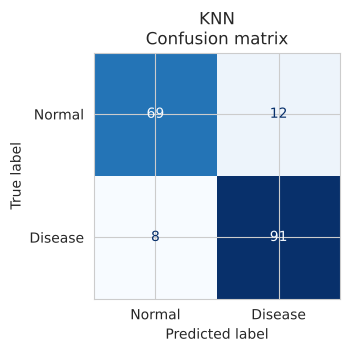

{'Model': 'KNN', 'Accuracy': 0.8889, 'Precision': 0.8835, 'Recall': 0.9192, 'F1-score': 0.901, 'Training Time (s)': 0.0021}


In [18]:
model = KNeighborsClassifier()
results_before["KNN"] = evaluate_model(model, X_train_scaled, X_test_scaled, y_train, y_test, name="KNN")

### 5.3 Logistic Regression

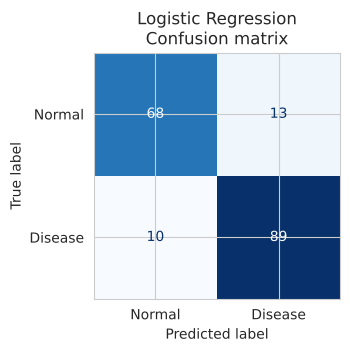

{'Model': 'Logistic Regression', 'Accuracy': 0.8722, 'Precision': 0.8725, 'Recall': 0.899, 'F1-score': 0.8856, 'Training Time (s)': 0.0042}


In [19]:
model = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000)
results_before["Logistic Regression"] = evaluate_model(model, X_train_scaled, X_test_scaled, y_train, y_test, name="Logistic Regression")

### 5.4 Decision Tree

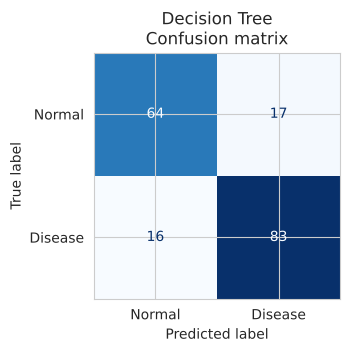

{'Model': 'Decision Tree', 'Accuracy': 0.8167, 'Precision': 0.83, 'Recall': 0.8384, 'F1-score': 0.8342, 'Training Time (s)': 0.0031}


In [20]:
model = DecisionTreeClassifier(random_state=RANDOM_STATE)
results_before["Decision Tree"] = evaluate_model(model, X_train_scaled, X_test_scaled, y_train, y_test, name="Decision Tree")

### 5.5 Random Forest

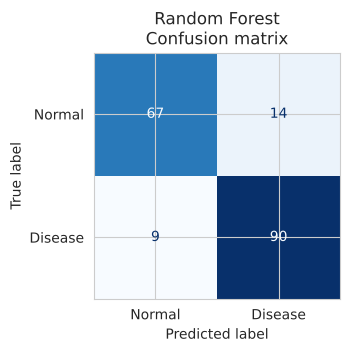

{'Model': 'Random Forest', 'Accuracy': 0.8722, 'Precision': 0.8654, 'Recall': 0.9091, 'F1-score': 0.8867, 'Training Time (s)': 0.1513}


In [21]:
model = RandomForestClassifier(random_state=RANDOM_STATE)
results_before["Random Forest"] = evaluate_model(model, X_train_scaled, X_test_scaled, y_train, y_test, name="Random Forest")

### 5.6 Comparison table and bar chart of all four models

,Accuracy,Precision,Recall,F1-score,Training Time (s)
KNN,0.8889,0.8835,0.9192,0.9010,0.0021
Logistic Regression,0.8722,0.8725,0.8990,0.8856,0.0042
Decision Tree,0.8167,0.8300,0.8384,0.8342,0.0031
Random Forest,0.8722,0.8654,0.9091,0.8867,0.1513


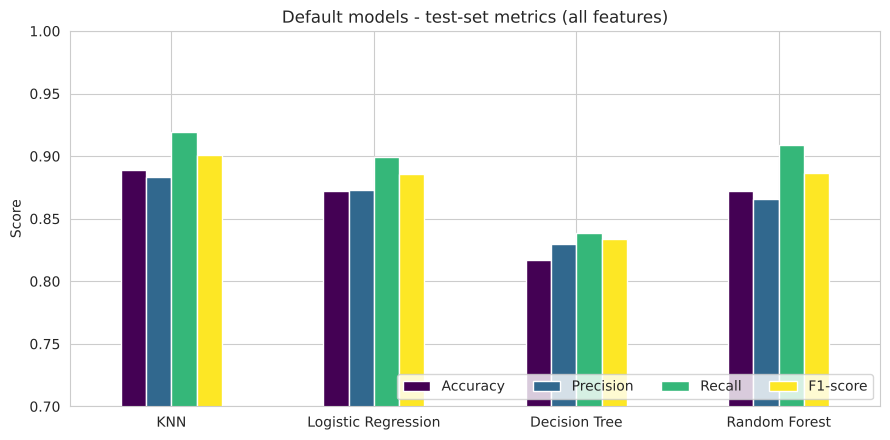

In [22]:
metric_cols = ["Accuracy", "Precision", "Recall", "F1-score"]
table_before = pd.DataFrame(results_before).T.drop(columns="Model")
table_before = table_before.astype(float)
display(table_before.round(4))

table_before[metric_cols].plot(kind="bar", figsize=(9, 4.5), rot=0, colormap="viridis")
plt.title("Default models - test-set metrics (all features)")
plt.ylabel("Score")
plt.ylim(0.7, 1.0)
plt.legend(loc="lower right", ncol=4)
plt.tight_layout()
plt.show()

**Q5.** Which model achieved the highest test accuracy? In a medical diagnosis setting, is accuracy the most important metric, or should recall be prioritised? Explain.

> ✍️ **Your answer:**
>
> On the default models, **KNN achieved the highest test accuracy (88.9%)**, followed by Logistic Regression and Random Forest (both 87.2%) and the Decision Tree (81.7%). KNN also had the best recall (91.9%) and F1 (0.901). The single, un-pruned Decision Tree is the weakest, as it overfits the training data.
>
> **Accuracy is not the most important metric in medical diagnosis; recall should be prioritised.** A false negative means a sick patient is told that they are healthy, so the disease goes untreated, which can be fatal. A false positive means a healthy patient is sent for additional tests, which is costly and stressful but far less dangerous. Accuracy hides this asymmetry because it counts both kinds of mistakes equally. In practice we want high recall while keeping precision acceptable (F1 or the precision-recall trade-off helps to monitor this). With that criterion KNN is again the best default model (recall 0.919), while the Decision Tree misses the most sick patients (recall 0.838).

---
## Task 6: Hyperparameter Tuning Using Cross-Validation

Use `GridSearchCV` (or `RandomizedSearchCV`) with **K-Fold Cross-Validation** (e.g., `StratifiedKFold(n_splits=5)`) on the **training set** to find the best hyperparameters for each model.

![kfold](attachment:kfold.png)

**Suggested hyperparameter grids** (you may extend them):

| Model | Hyperparameters to tune |
|---|---|
| KNN | `n_neighbors`, `weights`, `metric` |
| Logistic Regression | `C`, `penalty`, `solver` |
| Decision Tree | `max_depth`, `min_samples_split`, `min_samples_leaf`, `criterion` |
| Random Forest | `n_estimators`, `max_depth`, `min_samples_split`, `max_features` |

**Steps**
1. Define a parameter grid for each model.
2. Run the grid search with K-Fold cross-validation.
3. Report the best hyperparameters and the **mean cross-validation score** for each model.
4. Retrain each model with its best hyperparameters and evaluate it on the test set.
5. Compare the tuned models and identify the best-performing one.

### 6.1 Define the cross-validation strategy and parameter grids

In [23]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

param_grids = {
    "KNN": {
        "n_neighbors": list(range(3, 26, 2)),
        "weights": ["uniform", "distance"],
        "metric": ["euclidean", "manhattan", "chebyshev"],
    },
    "Logistic Regression": [
        {"solver": ["liblinear"], "penalty": ["l1", "l2"], "C": [0.01, 0.1, 1, 10, 100]},
        {"solver": ["lbfgs"], "penalty": ["l2"], "C": [0.01, 0.1, 1, 10, 100]},
    ],
    "Decision Tree": {
        "max_depth": [3, 5, 7, 10, None],
        "min_samples_split": [2, 5, 10],
        "min_samples_leaf": [1, 2, 4],
        "criterion": ["gini", "entropy"],
    },
    "Random Forest": {
        "n_estimators": [100, 200, 300],
        "max_depth": [None, 5, 10],
        "min_samples_split": [2, 5],
        "max_features": ["sqrt", "log2"],
    },
}

base_models = {
    "KNN": KNeighborsClassifier(),
    "Logistic Regression": LogisticRegression(random_state=RANDOM_STATE, max_iter=2000),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE),
}


def tune_and_evaluate(name, Xtr, Xte, ytr, yte, show_cm=True):
    """Grid search with stratified 5-fold CV on the training set, then evaluate best model on the test set."""
    gs = GridSearchCV(base_models[name], param_grids[name], cv=cv, scoring="accuracy", n_jobs=-1, refit=True)
    s = time.perf_counter()
    gs.fit(Xtr, ytr)
    search_time = time.perf_counter() - s

    best = gs.best_estimator_
    y_pred = best.predict(Xte)
    res = {
        "Best CV Accuracy": gs.best_score_,
        "Accuracy": accuracy_score(yte, y_pred),
        "Precision": precision_score(yte, y_pred),
        "Recall": recall_score(yte, y_pred),
        "F1-score": f1_score(yte, y_pred),
        "Training Time (s)": avg_fit_time(best, Xtr, ytr),   # one fit with the best hyperparameters
        "Grid Search Time (s)": search_time,
        "Best Params": gs.best_params_,
    }
    print(f"Best hyperparameters : {gs.best_params_}")
    print(f"Mean CV accuracy     : {gs.best_score_:.4f}")
    print(f"Test  Acc/Prec/Rec/F1: {res['Accuracy']:.4f} / {res['Precision']:.4f} / {res['Recall']:.4f} / {res['F1-score']:.4f}")
    if show_cm:
        fig, ax = plt.subplots(figsize=(3.6, 3.2))
        ConfusionMatrixDisplay(confusion_matrix(yte, y_pred), display_labels=["Normal", "Disease"]).plot(
            ax=ax, cmap="Blues", colorbar=False)
        ax.set_title(f"{name} (tuned)\nConfusion matrix")
        plt.show()
    return res, gs


results_tuned = {}
grids = {}
print("5-fold stratified CV defined. Parameter grids ready for:", list(param_grids))

5-fold stratified CV defined. Parameter grids ready for: ['KNN', 'Logistic Regression', 'Decision Tree', 'Random Forest']


### 6.2 Tune KNN

Best hyperparameters : {'metric': 'manhattan', 'n_neighbors': 11, 'weights': 'distance'}
Mean CV accuracy     : 0.8803
Test  Acc/Prec/Rec/F1: 0.8944 / 0.8922 / 0.9192 / 0.9055


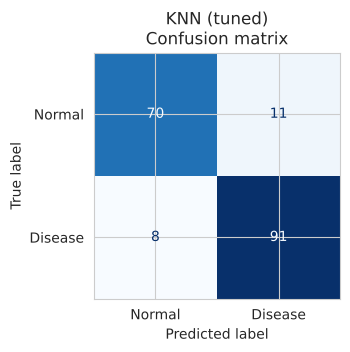

In [24]:
results_tuned["KNN"], grids["KNN"] = tune_and_evaluate("KNN", X_train_scaled, X_test_scaled, y_train, y_test)

### 6.3 Tune Logistic Regression

Best hyperparameters : {'C': 0.1, 'penalty': 'l2', 'solver': 'lbfgs'}
Mean CV accuracy     : 0.8678
Test  Acc/Prec/Rec/F1: 0.8778 / 0.8738 / 0.9091 / 0.8911


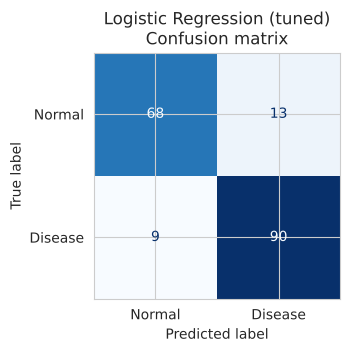

In [25]:
results_tuned["Logistic Regression"], grids["Logistic Regression"] = tune_and_evaluate("Logistic Regression", X_train_scaled, X_test_scaled, y_train, y_test)

### 6.4 Tune Decision Tree

Best hyperparameters : {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2}
Mean CV accuracy     : 0.8344
Test  Acc/Prec/Rec/F1: 0.8222 / 0.8764 / 0.7879 / 0.8298


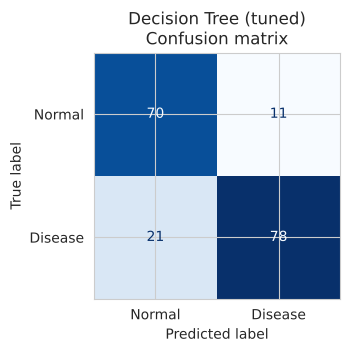

In [26]:
results_tuned["Decision Tree"], grids["Decision Tree"] = tune_and_evaluate("Decision Tree", X_train_scaled, X_test_scaled, y_train, y_test)

### 6.5 Tune Random Forest

Best hyperparameters : {'max_depth': None, 'max_features': 'sqrt', 'min_samples_split': 2, 'n_estimators': 300}
Mean CV accuracy     : 0.8748
Test  Acc/Prec/Rec/F1: 0.8667 / 0.8571 / 0.9091 / 0.8824


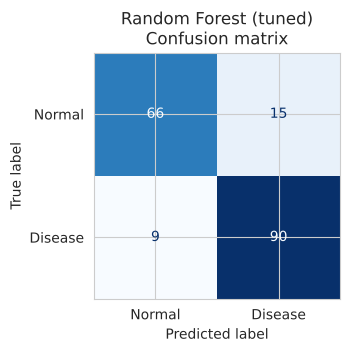

In [27]:
results_tuned["Random Forest"], grids["Random Forest"] = tune_and_evaluate("Random Forest", X_train_scaled, X_test_scaled, y_train, y_test)

### 6.6 Compare tuned models (test-set metrics, best CV score, training time)

,Best CV Accuracy,Accuracy,Precision,Recall,F1-score,Training Time (s),Grid Search Time (s)
KNN,0.8803,0.8944,0.8922,0.9192,0.9055,0.0011,2.0733
Logistic Regression,0.8678,0.8778,0.8738,0.9091,0.8911,0.0022,0.2772
Decision Tree,0.8344,0.8222,0.8764,0.7879,0.8298,0.0021,1.9653
Random Forest,0.8748,0.8667,0.8571,0.9091,0.8824,0.4156,49.9853


,CV acc (default),CV acc (tuned),CV change,Accuracy (default),Accuracy (tuned),Change,F1 (default),F1 (tuned),F1 change
KNN,0.8581,0.8803,0.0223,0.8889,0.8944,0.0056,0.9010,0.9055,0.0045
Logistic Regression,0.8623,0.8678,0.0056,0.8722,0.8778,0.0056,0.8856,0.8911,0.0055
Decision Tree,0.7510,0.8344,0.0834,0.8167,0.8222,0.0056,0.8342,0.8298,-0.0044
Random Forest,0.8706,0.8748,0.0042,0.8722,0.8667,-0.0056,0.8867,0.8824,-0.0043


Best tuned model by test accuracy: KNN


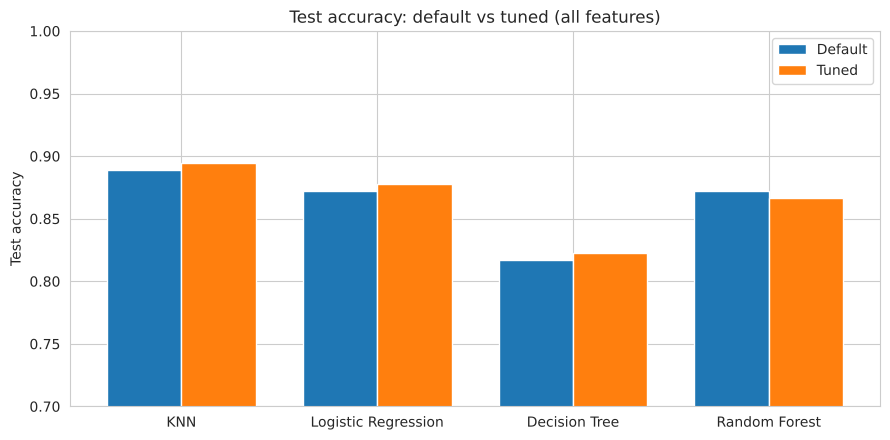

In [28]:
table_tuned = pd.DataFrame(results_tuned).T.drop(columns="Best Params")
cols = ["Best CV Accuracy", "Accuracy", "Precision", "Recall", "F1-score", "Training Time (s)", "Grid Search Time (s)"]
table_tuned = table_tuned[cols].astype(float)
display(table_tuned.round(4))

# Cross-validated accuracy of the DEFAULT models (same folds) - a steadier yardstick than one 180-patient test set
default_models = {
    "KNN": KNeighborsClassifier(),
    "Logistic Regression": LogisticRegression(random_state=RANDOM_STATE, max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE),
}
default_cv = pd.Series({n: cross_val_score(m, X_train_scaled, y_train, cv=cv, scoring="accuracy").mean()
                        for n, m in default_models.items()})

# Improvement over the default models
improve = pd.DataFrame({
    "CV acc (default)": default_cv,
    "CV acc (tuned)": table_tuned["Best CV Accuracy"],
    "CV change": table_tuned["Best CV Accuracy"] - default_cv,
    "Accuracy (default)": table_before["Accuracy"],
    "Accuracy (tuned)": table_tuned["Accuracy"],
    "Change": table_tuned["Accuracy"] - table_before["Accuracy"],
    "F1 (default)": table_before["F1-score"],
    "F1 (tuned)": table_tuned["F1-score"],
    "F1 change": table_tuned["F1-score"] - table_before["F1-score"],
})
display(improve.round(4))

print("Best tuned model by test accuracy:", table_tuned["Accuracy"].idxmax())

fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(table_tuned)); w = 0.38
ax.bar(x - w/2, table_before["Accuracy"], w, label="Default")
ax.bar(x + w/2, table_tuned["Accuracy"], w, label="Tuned")
ax.set_xticks(x); ax.set_xticklabels(table_tuned.index)
ax.set_ylim(0.7, 1.0); ax.set_ylabel("Test accuracy"); ax.legend()
ax.set_title("Test accuracy: default vs tuned (all features)")
plt.tight_layout(); plt.show()

**Q6.** Did hyperparameter tuning improve every model? Which model benefited the most, and why do you think that is?

> ✍️ **Your answer:**
>
> **No, tuning did not improve every model, and the improvements on the test set are small.** On the 180-patient test set, KNN, Logistic Regression and the Decision Tree each gained +0.56 percentage points in accuracy (exactly **one more patient classified correctly**), while Random Forest lost 0.56 points (one patient fewer; its default was already good). One test patient is worth 0.56 points, so these differences are within noise.
>
> The 5-fold CV scores on the 719 training patients are a more stable yardstick (default → tuned): KNN 0.858 → 0.880 (+2.2 pts), Logistic Regression 0.862 → 0.868 (+0.6), Random Forest 0.871 → 0.875 (+0.4) and **Decision Tree 0.751 → 0.834 (+8.3 pts)**.
>
> **The Decision Tree benefited the most.** An unconstrained tree grows until it memorises the training data (high variance); the search selected `max_depth=5` with the entropy criterion, which regularises it and gives the largest CV gain. KNN also benefited visibly because `n_neighbors=5` was replaced by 11 with distance weighting and Manhattan distance. Logistic Regression and Random Forest are already well regularised/robust out of the box (default `C=1`, an ensemble that averages many trees), so there was little left to gain. Note that the best CV score is slightly optimistic because it was also used to choose the winner, and that the Decision Tree's test accuracy (82.2%) remains clearly the lowest.

---
## Task 7: Dimensionality Reduction Using PCA

**Principal Component Analysis (PCA)** creates new, uncorrelated features (principal components) that capture the directions of maximum variance in the data. Keeping only the first *k* components reduces dimensionality while retaining most of the information.

![pca](attachment:pca.png)

**Steps**
1. Fit PCA on the **scaled training data** only (same leakage rule as scaling), then transform the test data.
2. Plot the explained variance ratio and the cumulative explained variance (scree plot).
3. Determine the number of components needed to retain **95%** of the variance.
4. Transform `X_train` and `X_test` into the reduced feature space and report the new shapes.

> 💡 *Hint:* `PCA(n_components=0.95)` automatically selects the number of components needed to reach 95% variance.

### 7.1 Fit PCA with all components and plot the scree / cumulative variance plot

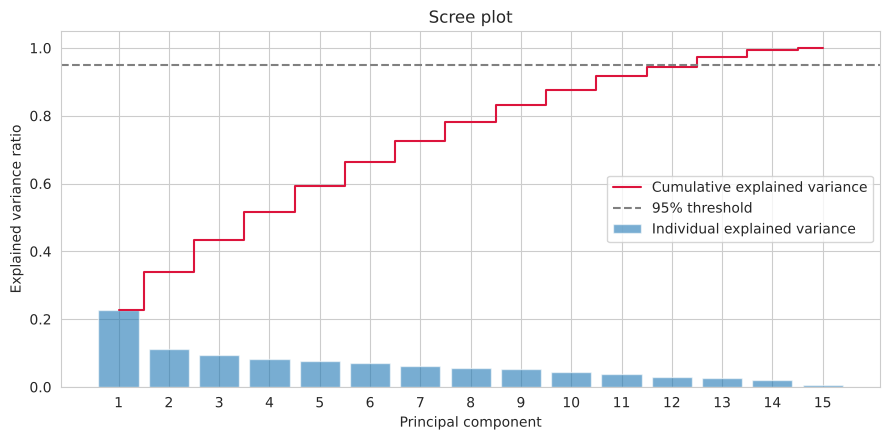

      Explained variance  Cumulative
PC1               0.2270      0.2270
PC2               0.1129      0.3399
PC3               0.0939      0.4338
PC4               0.0820      0.5158
PC5               0.0779      0.5937
PC6               0.0697      0.6634
PC7               0.0621      0.7255
PC8               0.0555      0.7811
PC9               0.0521      0.8331
PC10              0.0434      0.8766
PC11              0.0395      0.9160
PC12              0.0285      0.9445
PC13              0.0275      0.9720
PC14              0.0215      0.9935
PC15              0.0065      1.0000


In [29]:
pca_full = PCA(random_state=RANDOM_STATE).fit(X_train_scaled)    # fit on TRAINING data only

evr = pca_full.explained_variance_ratio_
cum_evr = np.cumsum(evr)
comp = np.arange(1, len(evr) + 1)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(comp, evr, alpha=0.6, label="Individual explained variance")
ax.step(comp, cum_evr, where="mid", color="crimson", label="Cumulative explained variance")
ax.axhline(0.95, color="grey", ls="--", label="95% threshold")
ax.set_xlabel("Principal component"); ax.set_ylabel("Explained variance ratio")
ax.set_xticks(comp); ax.set_title("Scree plot"); ax.legend(loc="center right")
plt.tight_layout(); plt.show()

print(pd.DataFrame({"Explained variance": evr, "Cumulative": cum_evr}, index=[f"PC{i}" for i in comp]).round(4))

### 7.2 Determine the number of components for 95% variance

In [30]:
n_components_95 = int(np.argmax(cum_evr >= 0.95) + 1)
print("Components needed for >= 95% variance:", n_components_95)
print(f"Variance retained with {n_components_95} components: {cum_evr[n_components_95 - 1]:.4f}")
print(f"Original features: {X_train_scaled.shape[1]}  ->  reduced to: {n_components_95}")
print(f"Reduction in number of features: {(1 - n_components_95 / X_train_scaled.shape[1]) * 100:.1f}%")

Components needed for >= 95% variance: 13
Variance retained with 13 components: 0.9720
Original features: 15  ->  reduced to: 13
Reduction in number of features: 13.3%


### 7.3 Transform the training and testing sets

In [31]:
pca = PCA(n_components=0.95, random_state=RANDOM_STATE)
X_train_pca = pca.fit_transform(X_train_scaled)    # fit on training data only
X_test_pca = pca.transform(X_test_scaled)

print("PCA components kept:", pca.n_components_)
print("X_train before PCA:", X_train_scaled.shape, "-> after PCA:", X_train_pca.shape)
print("X_test  before PCA:", X_test_scaled.shape, "-> after PCA:", X_test_pca.shape)

PCA components kept: 13
X_train before PCA: (719, 15) -> after PCA: (719, 13)
X_test  before PCA: (180, 15) -> after PCA: (180, 13)


### 7.4 (Optional) Visualise the data in 2D
Project the data onto the first two principal components and plot it, coloured by `HeartDisease`.

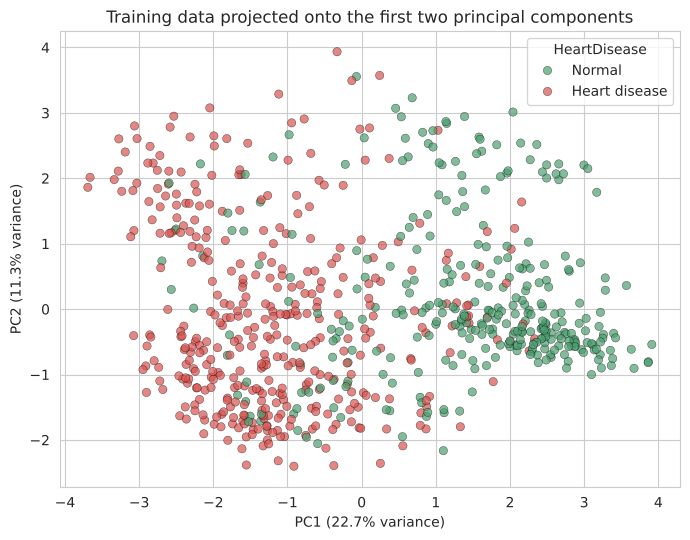

In [32]:
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE).fit(X_train_scaled)
Z = pca_2d.transform(X_train_scaled)

plt.figure(figsize=(7, 5.5))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=y_train.map({0: "Normal", 1: "Heart disease"}),
                palette=["#4c9f70", "#d9534f"], alpha=0.7, edgecolor="k", linewidth=0.3)
plt.xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.title("Training data projected onto the first two principal components")
plt.legend(title="HeartDisease")
plt.tight_layout(); plt.show()

**Q7.** How many principal components are needed to retain 95% of the variance? By what percentage was the number of features reduced?

> ✍️ **Your answer:**
>
> **13 principal components** are needed to retain at least 95% of the variance (12 components give 94.5%, 13 give **97.2%**). The number of features is reduced from 15 to 13, i.e. by only **13.3%**.
>
> The variance is spread almost evenly: PC1 explains only 22.7% and PC2 11.3% (34% together, see the 2D plot), because most of the 15 inputs are weakly correlated one-hot/binary columns. There is no small set of dominant directions, so PCA cannot compress this data set much.

---
## Task 8: Model Training and Evaluation After PCA

Retrain the four classifiers on the **PCA-transformed** data.

**Steps**
1. Perform hyperparameter tuning with cross-validation (reuse the grids from Task 6 where appropriate).
2. Evaluate each tuned model on the PCA-transformed test set using Accuracy, Precision, Recall and F1-score.
3. Record the **training time** for each model.
4. Identify the best-performing model after PCA.

### 8.1 KNN after PCA

Best hyperparameters : {'metric': 'manhattan', 'n_neighbors': 23, 'weights': 'distance'}
Mean CV accuracy     : 0.8804
Test  Acc/Prec/Rec/F1: 0.9056 / 0.9020 / 0.9293 / 0.9154


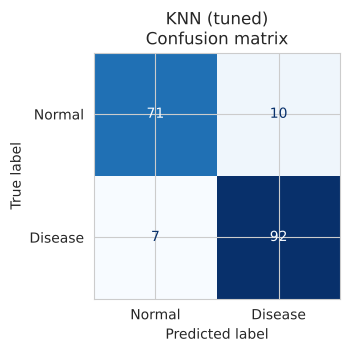

In [33]:
results_pca = {}
grids_pca = {}
results_pca["KNN"], grids_pca["KNN"] = tune_and_evaluate("KNN", X_train_pca, X_test_pca, y_train, y_test)

### 8.2 Logistic Regression after PCA

Best hyperparameters : {'C': 0.1, 'penalty': 'l2', 'solver': 'liblinear'}
Mean CV accuracy     : 0.8678
Test  Acc/Prec/Rec/F1: 0.8778 / 0.8812 / 0.8990 / 0.8900


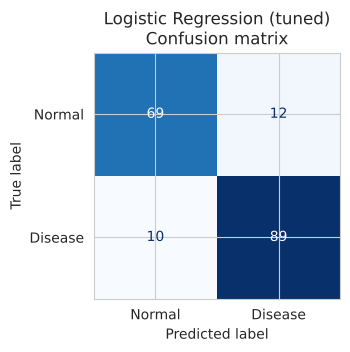

In [34]:
results_pca["Logistic Regression"], grids_pca["Logistic Regression"] = tune_and_evaluate("Logistic Regression", X_train_pca, X_test_pca, y_train, y_test)

### 8.3 Decision Tree after PCA

Best hyperparameters : {'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
Mean CV accuracy     : 0.8345
Test  Acc/Prec/Rec/F1: 0.8722 / 0.8800 / 0.8889 / 0.8844


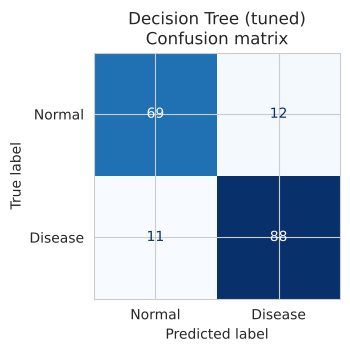

In [35]:
results_pca["Decision Tree"], grids_pca["Decision Tree"] = tune_and_evaluate("Decision Tree", X_train_pca, X_test_pca, y_train, y_test)

### 8.4 Random Forest after PCA

Best hyperparameters : {'max_depth': 5, 'max_features': 'sqrt', 'min_samples_split': 2, 'n_estimators': 100}
Mean CV accuracy     : 0.8692
Test  Acc/Prec/Rec/F1: 0.8944 / 0.8846 / 0.9293 / 0.9064


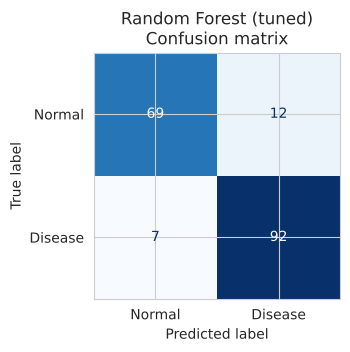

In [36]:
results_pca["Random Forest"], grids_pca["Random Forest"] = tune_and_evaluate("Random Forest", X_train_pca, X_test_pca, y_train, y_test)

### 8.5 Comparison table of all four models after PCA

In [37]:
table_pca = pd.DataFrame(results_pca).T.drop(columns="Best Params")
table_pca = table_pca[cols].astype(float)
display(table_pca.round(4))

print("Best model after PCA (test accuracy):", table_pca["Accuracy"].idxmax())
print("Best model before PCA (tuned, test accuracy):", table_tuned["Accuracy"].idxmax())

print("\nBest hyperparameters after PCA:")
for k, v in results_pca.items():
    print(f"  {k:20s} {v['Best Params']}")

,Best CV Accuracy,Accuracy,Precision,Recall,F1-score,Training Time (s),Grid Search Time (s)
KNN,0.8804,0.9056,0.9020,0.9293,0.9154,0.0016,2.0885
Logistic Regression,0.8678,0.8778,0.8812,0.8990,0.8900,0.0017,0.2808
Decision Tree,0.8345,0.8722,0.8800,0.8889,0.8844,0.0034,2.9248
Random Forest,0.8692,0.8944,0.8846,0.9293,0.9064,0.1612,62.0988


Best model after PCA (test accuracy): KNN
Best model before PCA (tuned, test accuracy): KNN

Best hyperparameters after PCA:
  KNN                  {'metric': 'manhattan', 'n_neighbors': 23, 'weights': 'distance'}
  Logistic Regression  {'C': 0.1, 'penalty': 'l2', 'solver': 'liblinear'}
  Decision Tree        {'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
  Random Forest        {'max_depth': 5, 'max_features': 'sqrt', 'min_samples_split': 2, 'n_estimators': 100}


**Q8.** Which model performed best after PCA? Is it the same model that performed best before PCA?

> ✍️ **Your answer:**
>
> After PCA, **KNN was again the best model** with a test accuracy of **90.6%** (F1 0.915, recall 0.929), followed by Random Forest (89.4%), Logistic Regression (87.8%) and the Decision Tree (87.2%). **Yes, it is the same model that performed best before PCA** (tuned KNN, 89.4%).
>
> The ranking of the others changed: Random Forest moved clearly ahead of Logistic Regression, and the Decision Tree closed most of the gap to the other models (82.2% → 87.2%). Details of what this means are discussed in Task 9.

---
## Task 9: Comparative Analysis and Discussion

### 9.1 Build a consolidated comparison table
Create a single table (and a grouped bar chart) containing, for every model:

| Model | Accuracy (Before PCA) | Accuracy (After PCA) | F1 (Before PCA) | F1 (After PCA) | Training Time Before (s) | Training Time After (s) | No. of Features |
|---|---|---|---|---|---|---|---|
| KNN | | | | | | | |
| Logistic Regression | | | | | | | |
| Decision Tree | | | | | | | |
| Random Forest | | | | | | | |

In [38]:
n_feat_before = X_train_scaled.shape[1]
n_feat_after = X_train_pca.shape[1]

comparison = pd.DataFrame({
    "Accuracy (Before PCA)": table_tuned["Accuracy"],
    "Accuracy (After PCA)": table_pca["Accuracy"],
    "F1 (Before PCA)": table_tuned["F1-score"],
    "F1 (After PCA)": table_pca["F1-score"],
    "Training Time Before (s)": table_tuned["Training Time (s)"],
    "Training Time After (s)": table_pca["Training Time (s)"],
    "No. of Features (Before -> After)": f"{n_feat_before} -> {n_feat_after}",
})
comparison.index.name = "Model"
display(comparison.round(4))

delta = pd.DataFrame({
    "Accuracy change": comparison["Accuracy (After PCA)"] - comparison["Accuracy (Before PCA)"],
    "F1 change": comparison["F1 (After PCA)"] - comparison["F1 (Before PCA)"],
    "Training-time change (%)": (comparison["Training Time After (s)"] / comparison["Training Time Before (s)"] - 1) * 100,
})
display(delta.round(4))

,Accuracy (Before PCA),Accuracy (After PCA),F1 (Before PCA),F1 (After PCA),Training Time Before (s),Training Time After (s),No. of Features (Before -> After)
Model,,,,,,,
KNN,0.8944,0.9056,0.9055,0.9154,0.0011,0.0016,15 -> 13
Logistic Regression,0.8778,0.8778,0.8911,0.8900,0.0022,0.0017,15 -> 13
Decision Tree,0.8222,0.8722,0.8298,0.8844,0.0021,0.0034,15 -> 13
Random Forest,0.8667,0.8944,0.8824,0.9064,0.4156,0.1612,15 -> 13


,Accuracy change,F1 change,Training-time change (%)
Model,,,
KNN,0.0111,0.0100,43.7389
Logistic Regression,0.0000,-0.0011,-23.4367
Decision Tree,0.0500,0.0546,66.5272
Random Forest,0.0278,0.0241,-61.2069


### 9.2 Visualise the before vs after PCA comparison

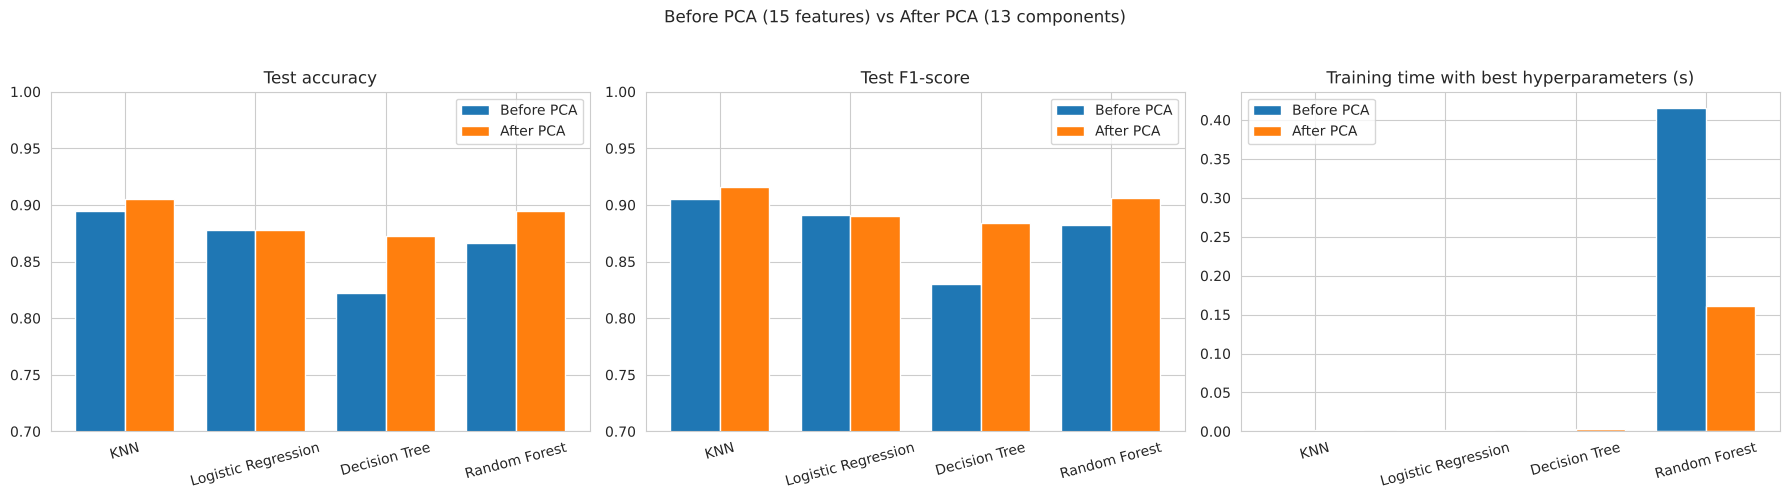

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
x = np.arange(len(comparison)); w = 0.38
labels = comparison.index

for ax, (b, a, title, ylim) in zip(axes[:2], [
        ("Accuracy (Before PCA)", "Accuracy (After PCA)", "Test accuracy", (0.7, 1.0)),
        ("F1 (Before PCA)", "F1 (After PCA)", "Test F1-score", (0.7, 1.0))]):
    ax.bar(x - w/2, comparison[b], w, label="Before PCA")
    ax.bar(x + w/2, comparison[a], w, label="After PCA")
    ax.set_xticks(x); ax.set_xticklabels(labels, rotation=15)
    ax.set_ylim(*ylim); ax.set_title(title); ax.legend()

axes[2].bar(x - w/2, comparison["Training Time Before (s)"], w, label="Before PCA")
axes[2].bar(x + w/2, comparison["Training Time After (s)"], w, label="After PCA")
axes[2].set_xticks(x); axes[2].set_xticklabels(labels, rotation=15)
axes[2].set_title("Training time with best hyperparameters (s)"); axes[2].legend()

plt.suptitle(f"Before PCA ({n_feat_before} features) vs After PCA ({n_feat_after} components)", y=1.03)
plt.tight_layout(); plt.show()

### 9.3 Discussion Questions

**Q9a.** Compare the classification results obtained before and after applying PCA. Which models improved, and which declined?

> ✍️ **Your answer:**
>
> **Accuracy / F1 before → after PCA (tuned models):**
>
> - **KNN:** 89.4% → 90.6% (+1.1 pts, 2 more patients correct); F1 0.906 → 0.915. **Improved slightly.**
> - **Logistic Regression:** 87.8% → 87.8% (unchanged); F1 0.891 → 0.890. **Unchanged.**
> - **Decision Tree:** 82.2% → 87.2% (+5.0 pts); F1 0.830 → 0.884. **Biggest improvement.**
> - **Random Forest:** 86.7% → 89.4% (+2.8 pts); F1 0.882 → 0.906. **Improved.**
>
> No model declined in accuracy. However, these gains should be read with caution: the test set has only 180 patients (one patient = 0.56 pts), and the cross-validated scores on the training set barely moved (KNN 0.880 → 0.880, Logistic Regression 0.868 → 0.868, Decision Tree 0.834 → 0.835, Random Forest 0.875 → 0.869). So the test-set improvements are mostly attributable to this particular split rather than to a real effect of PCA.

**Q9b.** Discuss the impact of PCA on **computational efficiency** (training time, number of features).

> ✍️ **Your answer:**
>
> **Number of features:** 15 → 13 (-13.3%), a modest reduction.
>
> **Training time (tuned model, average of 10 fits):** Random Forest **0.42 s → 0.16 s (-61%)** and Logistic Regression 0.0022 s → 0.0017 s (-23%) became faster, whereas KNN (0.0011 s → 0.0016 s) and the Decision Tree (0.0021 s → 0.0034 s) were slightly slower. The Decision Tree is slower because the 13 PCA components are dense continuous columns, each of which has to be sorted and scanned for split points, whereas the original data contain many 0/1 columns that are trivial to split; the tuned PCA models are also different models (e.g. a shallower tree, 23 instead of 11 neighbours for KNN).
>
> Apart from Random Forest, all times are in the millisecond range, so those differences are negligible and partly timing noise (they change a little from run to run). Only Random Forest shows a meaningful and consistent saving, and the full grid search for it was not faster (about 50 s vs 62 s; this depends on machine load and on which hyperparameters are tried). KNN's cost is mostly paid at prediction time and scales with the number of features.
>
> **Conclusion:** PCA gives only a small efficiency gain here because the data set is small (899 × 15) and only 2 dimensions could be dropped. The additional cost of fitting PCA and transforming new data must also be counted.

**Q9c.** Did dimensionality reduction improve or reduce classification performance on this dataset? Give possible reasons (e.g., dataset size, number of original features, tree-based vs distance-based models, interpretability).

> ✍️ **Your answer:**
>
> **On this single test split the classification performance appeared to improve (KNN +1.1, Random Forest +2.8, Decision Tree +5.0 points, Logistic Regression unchanged), but the cross-validation scores show no real change,** so the honest conclusion is that PCA neither clearly helped nor hurt. It certainly did not "reduce" performance. Possible reasons:
>
> - **Almost no information was removed.** With 13 of 15 components (97.2% of the variance) PCA is nearly a pure rotation of the data, so there is little to lose.
> - **Logistic Regression is practically rotation-invariant**, which is why its results are identical before and after PCA (0.878, CV 0.868 in both cases).
> - **Tree-based models** can profit from PCA: components are uncorrelated and mix several binary/one-hot columns, which allows trees to split on combinations of features. For the Decision Tree most of its test gain is also random-split variation, since its CV score is unchanged (0.834 vs 0.835).
> - **KNN** is distance-based, so rotating the features keeps distances almost unchanged, but dropping the 2 weakest components acts like mild noise removal.
> - **Small data set:** 180 test patients means one patient changes accuracy by 0.56 points, so differences of 1-3 points are within noise. A repeated cross-validation or several random splits would be needed to prove any difference.
> - **PCA is unsupervised:** it keeps variance, not class-separating information, which is why in general it can lower accuracy.
> - **Interpretability is lost:** each component is a mix of all 15 features, so statements such as "ST_Slope_Flat and ExerciseAngina are the strongest predictors" are no longer possible with the PCA models.

**Q9d.** Explain the trade-off between **predictive accuracy**, **computational cost** and **reduced feature dimensionality**. In which real-world situations would you prefer to use PCA?

> ✍️ **Your answer:**
>
> **Trade-off.** More features keep more information and usually give the best accuracy and interpretability, but they raise training/prediction cost, memory and the risk of overfitting (the curse of dimensionality). PCA lowers dimensionality and cost and removes correlation between features, but it can discard class-relevant information if the components are cut too aggressively (choose 99% instead of 90%, and accuracy rises while the savings shrink), it adds a preprocessing step, and it makes the model harder to explain. Here the trade-off is almost neutral: accuracy stayed the same or looked a little better, but the feature reduction (15 → 13) and time saving (mainly Random Forest) are small.
>
> **When PCA is worth using:**
> - Data with **hundreds or thousands of correlated features** (genomics/gene expression, spectroscopy, image pixels, text embeddings, sensor streams), where training time and memory are a real bottleneck.
> - **Multicollinearity:** to stabilise linear/logistic regression coefficients.
> - **Visualisation** of high-dimensional data in 2D/3D to find clusters or outliers.
> - **Noise reduction/compression** and storage or transmission on resource-limited devices (e.g. edge/wearable ECG monitoring).
>
> **When to avoid it:** small, tabular, mostly categorical data like this one, or whenever the model must be explained to clinicians. In those cases feature selection or regularisation is usually preferable to PCA.

---
## Expected Outcome

At the end of this exercise, you should be able to:

- Perform data preprocessing and outlier removal.
- Encode categorical variables and scale numerical features.
- Build and evaluate multiple classification models.
- Perform hyperparameter tuning using cross-validation.
- Apply PCA for dimensionality reduction.
- Compare model performance before and after PCA.
- Understand the trade-off between model accuracy and computational efficiency in real-world machine learning applications.

---

> 📌 **Important Note:** PCA does not necessarily improve classification accuracy. Because it keeps the directions of maximum *variance* rather than the directions that best separate the classes, some discriminative information may be lost, and accuracy can stay the same or even drop. Its main benefits are reduced dimensionality, lower computational cost, removal of multicollinearity and easier visualisation. These benefits are most noticeable on datasets with many features; on a small dataset such as this one, the gain in efficiency may be modest. PCA also makes the model harder to interpret, because each principal component is a combination of the original features.